Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
       VISIONPORT - INFERENCE REQUEST TRACE SYSTEM

STEP 1: SYSTEM CONFIGURATION
-------------------------------------------------------
PyTorch Version: 2.14.1+cpu
GPU Available: False
Execution Hardware: CPU
Execution Device: cpu

STEP 2: MODEL INITIALIZATION
-------------------------------------------------------
YOLOv8 Model Loaded Successfully!
Model Architecture: YOLOv8
Model Variant: YOLOv8 Nano

STEP 3: FASTAPI INITIALIZATION
-------------------------------------------------------
Inference Trace API Created Successfully!

STEP 4: STARTING API SERVER
-------------------------------------------------------
FastAPI Server: RUNNING
API Address: http://127.0.0.1:8002
Health Endpoint: http://127.

Saving traffic image.jpg to traffic image.jpg
Image Uploaded Successfully!
Filename: traffic image.jpg

STEP 6: SENDING INFERENCE REQUEST
-------------------------------------------------------
API Request Successful!
HTTP Status: 200
Request ID: 69a5fc9a-6022-4d54-963b-48e2c7a6c34f
Request Status: success
Total Objects: 26

STEP 7: INFERENCE REQUEST TRACE
REQUEST ID: 69a5fc9a-6022-4d54-963b-48e2c7a6c34f
REQUEST TIMESTAMP: 2026-11-23T06:33:35.243800+00:00
----------------------------------------------------------------------

STAGE 1: API Input / Request Ingestion
Start: 2026-11-23T06:33:35.243817+00:00
End: 2026-11-23T06:33:35.243862+00:00
Duration: 0.045 ms

STAGE 2: Image Preprocessing
Start: 2026-11-23T06:33:35.243878+00:00
End: 2026-11-23T06:33:35.289267+00:00
Duration: 45.385 ms

STAGE 3: YOLOv8 Model Execution
Start: 2026-11-23T06:33:35.289293+00:00
End: 2026-11-23T06:33:42.019245+00:00
Duration: 6729.949 ms

STAGE 4: Postprocessing / Detection Extraction
Start: 2026-11-23T06:33

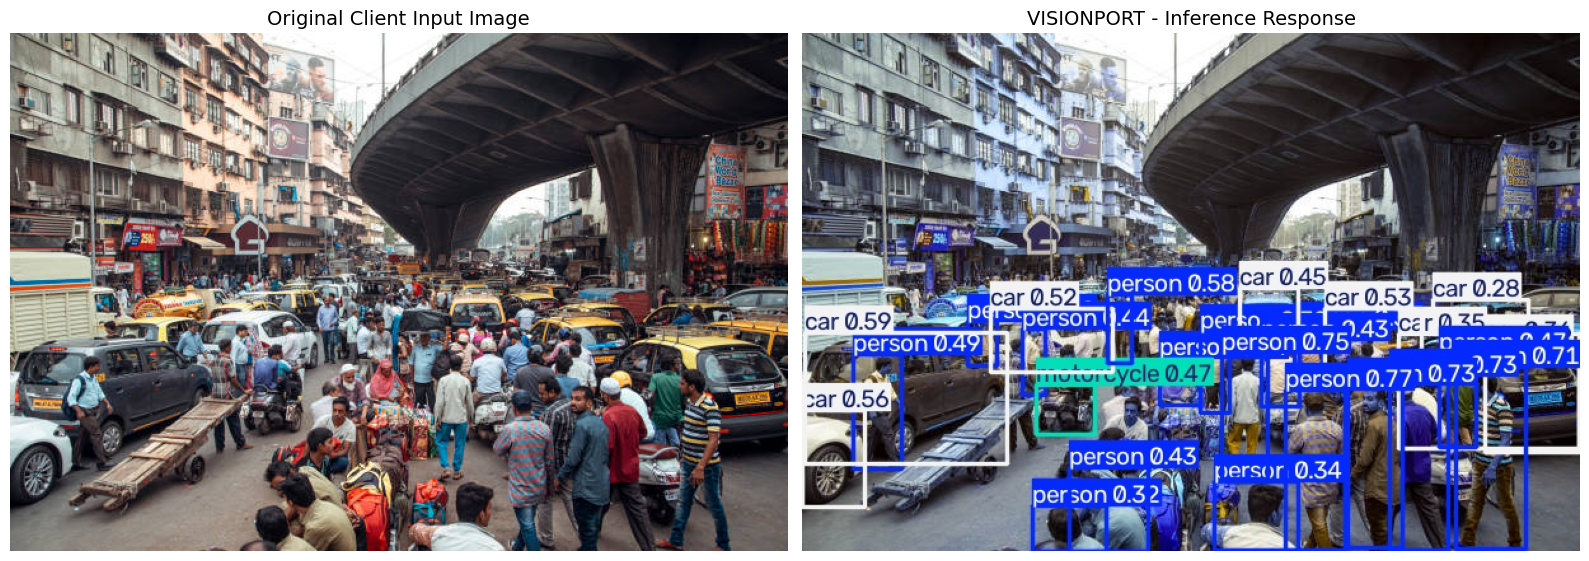


STEP 10: LIFECYCLE LATENCY ANALYSIS
-------------------------------------------------------


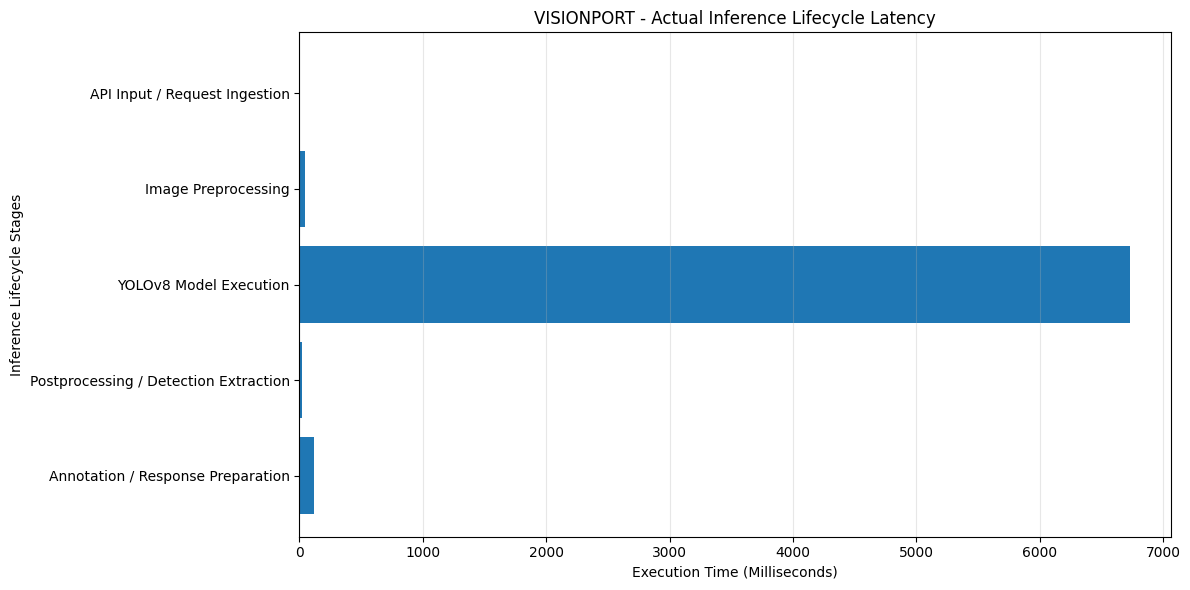


STEP 11: LATENCY DISTRIBUTION
-------------------------------------------------------


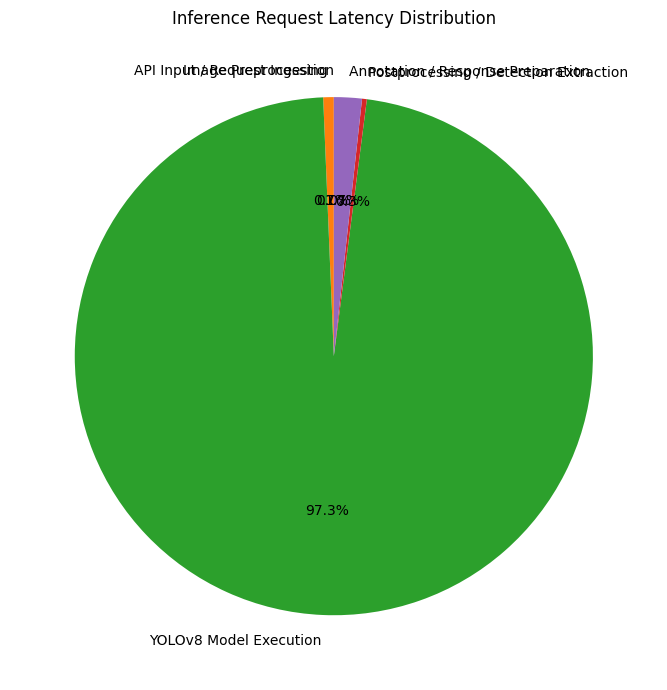


STEP 12: CONFIDENCE ANALYSIS
-------------------------------------------------------


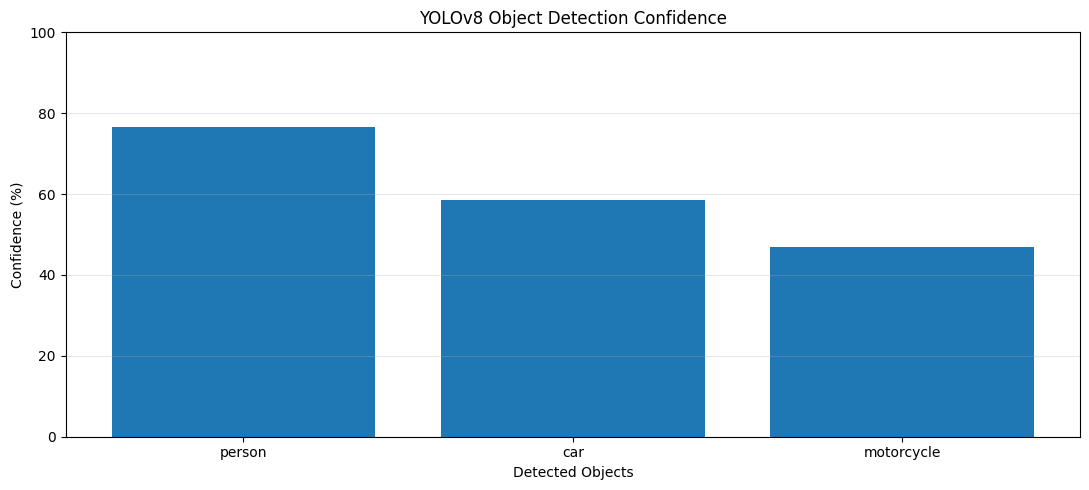


STEP 13: OUTPUT GENERATION
-------------------------------------------------------
Annotated Image Saved Successfully!
Output File: VisionPort_SKILL_3_Output.jpg
Inference Trace JSON Saved!
Trace File: VisionPort_SKILL_3_Trace.json


             VISIONPORT FINAL SYSTEM REPORT
Experiment                  : SKILL_3
API Input                   : SUCCESS
Image Validation            : SUCCESS
Image Preprocessing         : SUCCESS
YOLOv8 Model Execution      : SUCCESS
Object Detection            : COMPLETED
Postprocessing              : SUCCESS
Bounding Box Generation     : SUCCESS
API Response                : SUCCESS
Inference Request Trace     : GENERATED
Latency Analysis            : COMPLETED
Visualization               : COMPLETED
Output Image                : SAVED
Trace JSON                  : SAVED
----------------------------------------------------------------------
Hardware                    : CPU
GPU Available               : False
Total Objects Detected      : 26
Server Proc

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


ALL SKILL_3 OUTPUTS GENERATED SUCCESSFULLY!


In [1]:
# ============================================================
# VISIONPORT - SKILL-3
# INFERENCE REQUEST TRACE
# API INPUT, PREPROCESSING, MODEL EXECUTION AND RESPONSE
#
# Model       : YOLOv8 Nano
# API         : FastAPI
# Framework   : Ultralytics + PyTorch
# Platform    : Google Colab
# ============================================================


# 1. INSTALL DEPENDENCIES

!pip install -q ultralytics fastapi uvicorn python-multipart requests pillow


# 2. IMPORT REQUIRED LIBRARIES

import os
import time
import uuid
import base64
import threading
import requests
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime, timezone
from io import BytesIO
from PIL import Image, UnidentifiedImageError

from ultralytics import YOLO

from fastapi import FastAPI, UploadFile, File, HTTPException
from google.colab import files
import uvicorn


print("=" * 70)
print("       VISIONPORT - INFERENCE REQUEST TRACE SYSTEM")
print("=" * 70)


# 3. SYSTEM CONFIGURATION

print("\nSTEP 1: SYSTEM CONFIGURATION")
print("-" * 55)

gpu_available = torch.cuda.is_available()

if gpu_available:

    hardware = torch.cuda.get_device_name(0)
    DEVICE = "0"

else:

    hardware = "CPU"
    DEVICE = "cpu"


print("PyTorch Version:", torch.__version__)
print("GPU Available:", gpu_available)
print("Execution Hardware:", hardware)
print("Execution Device:", DEVICE)


# 4. LOAD YOLOv8 MODEL

print("\nSTEP 2: MODEL INITIALIZATION")
print("-" * 55)

model = YOLO("yolov8n.pt")

print("YOLOv8 Model Loaded Successfully!")
print("Model Architecture: YOLOv8")
print("Model Variant: YOLOv8 Nano")


# 5. CREATE FASTAPI APPLICATION

print("\nSTEP 3: FASTAPI INITIALIZATION")
print("-" * 55)

app = FastAPI(

    title="VisionPort Inference Trace API",

    description=(
        "Inference Request Tracing - "
        "API Input, Preprocessing, Model Execution and Response"
    ),

    version="3.0"

)


@app.get("/")
def home():

    return {

        "project": "VISIONPORT",

        "experiment": "SKILL_3",

        "status": "Running",

        "model": "YOLOv8 Nano",

        "purpose": "Inference Request Tracing"

    }


@app.get("/health")
def health():

    return {

        "api_status": "Healthy",

        "model_loaded": True,

        "hardware": hardware,

        "gpu_available": gpu_available

    }


# 6. INFERENCE REQUEST TRACE FUNCTION

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    request_id = str(uuid.uuid4())

    request_start = time.perf_counter()

    request_timestamp = datetime.now(
        timezone.utc
    ).isoformat()

    trace = []

    def record_stage(stage_name, start_time, start_timestamp):

        end_time = time.perf_counter()

        end_timestamp = datetime.now(
            timezone.utc
        ).isoformat()

        duration = (
            end_time - start_time
        ) * 1000

        trace.append({

            "stage": stage_name,

            "start_timestamp": start_timestamp,

            "end_timestamp": end_timestamp,

            "duration_ms": round(duration, 3)

        })

        return end_time


    # --------------------------------------------------------
    # STAGE 1: API INPUT / REQUEST INGESTION
    # --------------------------------------------------------

    stage_start = time.perf_counter()

    stage_timestamp = datetime.now(
        timezone.utc
    ).isoformat()

    if not file.filename:

        raise HTTPException(
            status_code=400,
            detail="Filename is missing."
        )

    content = await file.read()

    if not content:

        raise HTTPException(
            status_code=400,
            detail="Empty image received."
        )

    if len(content) > 10 * 1024 * 1024:

        raise HTTPException(
            status_code=413,
            detail="Image must be smaller than 10 MB."
        )

    record_stage(
        "API Input / Request Ingestion",
        stage_start,
        stage_timestamp
    )


    # --------------------------------------------------------
    # STAGE 2: INPUT PREPROCESSING
    # --------------------------------------------------------

    stage_start = time.perf_counter()

    stage_timestamp = datetime.now(
        timezone.utc
    ).isoformat()

    try:

        pil_image = Image.open(
            BytesIO(content)
        ).convert("RGB")

        pil_image.load()

    except (UnidentifiedImageError, OSError):

        raise HTTPException(
            status_code=400,
            detail="Invalid image file."
        )

    image_array = np.array(pil_image)

    if image_array.ndim != 3:

        raise HTTPException(
            status_code=400,
            detail="Invalid image dimensions."
        )

    height, width, channels = image_array.shape

    record_stage(
        "Image Preprocessing",
        stage_start,
        stage_timestamp
    )


    # --------------------------------------------------------
    # STAGE 3: MODEL EXECUTION / INFERENCE
    # --------------------------------------------------------

    stage_start = time.perf_counter()

    stage_timestamp = datetime.now(
        timezone.utc
    ).isoformat()

    results = model.predict(

        source=image_array,

        conf=0.25,

        imgsz=640,

        device=DEVICE,

        verbose=False

    )

    record_stage(
        "YOLOv8 Model Execution",
        stage_start,
        stage_timestamp
    )


    # --------------------------------------------------------
    # STAGE 4: POSTPROCESSING / DETECTION EXTRACTION
    # --------------------------------------------------------

    stage_start = time.perf_counter()

    stage_timestamp = datetime.now(
        timezone.utc
    ).isoformat()

    detections = []

    boxes = results[0].boxes

    if boxes is not None:

        for box in boxes:

            class_id = int(box.cls[0])

            confidence = float(box.conf[0])

            coordinates = [

                round(float(value), 2)

                for value in box.xyxy[0].tolist()

            ]

            detections.append({

                "object": model.names[class_id],

                "confidence": round(
                    confidence * 100, 2
                ),

                "bounding_box": coordinates

            })

    record_stage(
        "Postprocessing / Detection Extraction",
        stage_start,
        stage_timestamp
    )


    # --------------------------------------------------------
    # STAGE 5: ANNOTATION / RESPONSE PREPARATION
    # --------------------------------------------------------

    stage_start = time.perf_counter()

    stage_timestamp = datetime.now(
        timezone.utc
    ).isoformat()

    annotated_image = results[0].plot()

    success, encoded_image = cv2.imencode(
        ".jpg",
        annotated_image
    )

    if not success:

        raise HTTPException(
            status_code=500,
            detail="Image encoding failed."
        )

    image_base64 = base64.b64encode(
        encoded_image.tobytes()
    ).decode("utf-8")

    record_stage(
        "Annotation / Response Preparation",
        stage_start,
        stage_timestamp
    )


    # --------------------------------------------------------
    # FINAL REQUEST TIMING
    # --------------------------------------------------------

    total_server_time = (
        time.perf_counter() - request_start
    ) * 1000


    return {

        "project": "VISIONPORT",

        "experiment": "SKILL_3",

        "status": "success",

        "request_id": request_id,

        "request_timestamp": request_timestamp,

        "filename": file.filename,

        "model": "YOLOv8 Nano",

        "hardware": hardware,

        "image_information": {

            "width": width,

            "height": height,

            "channels": channels,

            "size_bytes": len(content)

        },

        "total_objects": len(detections),

        "detections": detections,

        "trace": trace,

        "total_server_processing_ms": round(
            total_server_time, 3
        ),

        "annotated_image": image_base64

    }


print("Inference Trace API Created Successfully!")


# 7. START FASTAPI SERVER

print("\nSTEP 4: STARTING API SERVER")
print("-" * 55)

API_HOST = "127.0.0.1"
API_PORT = 8002

API_URL = f"http://{API_HOST}:{API_PORT}"

server_errors = []


def start_server():

    try:

        uvicorn.run(

            app,

            host=API_HOST,

            port=API_PORT,

            log_level="error"

        )

    except Exception as error:

        server_errors.append(str(error))


server_thread = threading.Thread(

    target=start_server,

    daemon=True

)

server_thread.start()


# Wait for server readiness

api_ready = False

for attempt in range(40):

    if server_errors:

        raise RuntimeError(server_errors[0])

    try:

        response = requests.get(
            API_URL + "/health",
            timeout=2
        )

        if response.status_code == 200:

            api_ready = True
            break

    except requests.RequestException:

        time.sleep(1)


if not api_ready:

    raise RuntimeError(
        "FastAPI server could not start!"
    )


print("FastAPI Server: RUNNING")
print("API Address:", API_URL)
print("Health Endpoint:", API_URL + "/health")
print("Prediction Endpoint:", API_URL + "/predict")
print("Documentation:", API_URL + "/docs")


# 8. UPLOAD INPUT IMAGE

print("\nSTEP 5: IMAGE ACQUISITION")
print("-" * 55)

print("Upload a real photograph...")

uploaded = files.upload()

if not uploaded:

    raise ValueError("No image uploaded!")


image_path = list(uploaded.keys())[0]

print("Image Uploaded Successfully!")
print("Filename:", image_path)


# 9. SEND IMAGE THROUGH API

print("\nSTEP 6: SENDING INFERENCE REQUEST")
print("-" * 55)

client_request_start = time.perf_counter()

with open(image_path, "rb") as image_file:

    response = requests.post(

        API_URL + "/predict",

        files={

            "file": (

                os.path.basename(image_path),

                image_file,

                "application/octet-stream"

            )

        },

        timeout=180

    )


client_round_trip = (
    time.perf_counter() - client_request_start
) * 1000


if response.status_code != 200:

    raise RuntimeError(
        "API Request Failed: " + response.text
    )


output = response.json()


print("API Request Successful!")

print("HTTP Status:", response.status_code)

print("Request ID:", output["request_id"])

print("Request Status:", output["status"])

print("Total Objects:", output["total_objects"])


# 10. DISPLAY INFERENCE REQUEST TRACE

print("\nSTEP 7: INFERENCE REQUEST TRACE")
print("=" * 70)

print("REQUEST ID:", output["request_id"])

print("REQUEST TIMESTAMP:", output["request_timestamp"])

print("-" * 70)

for index, stage in enumerate(output["trace"]):

    print(f"\nSTAGE {index + 1}: {stage['stage']}")

    print(
        "Start:",
        stage["start_timestamp"]
    )

    print(
        "End:",
        stage["end_timestamp"]
    )

    print(
        "Duration:",
        stage["duration_ms"],
        "ms"
    )


print("\n" + "-" * 70)

print(
    "Total Server Processing:",
    output["total_server_processing_ms"],
    "ms"
)

print(
    "Client API Round Trip:",
    round(client_round_trip, 3),
    "ms"
)

print("=" * 70)


# 11. DISPLAY DETECTED OBJECTS

print("\nSTEP 8: OBJECT DETECTION RESULTS")
print("-" * 55)

detections = output["detections"]

if detections:

    for index, detection in enumerate(detections):

        print(f"\nObject {index + 1}")

        print(
            "Name:",
            detection["object"]
        )

        print(
            "Confidence:",
            detection["confidence"],
            "%"
        )

        print(
            "Bounding Box:",
            detection["bounding_box"]
        )

else:

    print("No objects detected.")


# 12. DISPLAY ORIGINAL AND ANNOTATED IMAGE

print("\nSTEP 9: IMAGE VISUALIZATION")
print("-" * 55)

original_image = cv2.imread(image_path)

original_rgb = cv2.cvtColor(
    original_image,
    cv2.COLOR_BGR2RGB
)


annotated_bytes = base64.b64decode(
    output["annotated_image"]
)

annotated_array = np.frombuffer(
    annotated_bytes,
    dtype=np.uint8
)

annotated_bgr = cv2.imdecode(
    annotated_array,
    cv2.IMREAD_COLOR
)

annotated_rgb = cv2.cvtColor(
    annotated_bgr,
    cv2.COLOR_BGR2RGB
)


plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)

plt.imshow(original_rgb)

plt.title(
    "Original Client Input Image",
    fontsize=14
)

plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(annotated_rgb)

plt.title(
    "VISIONPORT - Inference Response",
    fontsize=14
)

plt.axis("off")

plt.tight_layout()

plt.show()


# 13. LIFECYCLE LATENCY BREAKDOWN

print("\nSTEP 10: LIFECYCLE LATENCY ANALYSIS")
print("-" * 55)

stage_names = [

    stage["stage"]

    for stage in output["trace"]

]

stage_times = [

    stage["duration_ms"]

    for stage in output["trace"]

]


plt.figure(figsize=(12, 6))

plt.barh(

    stage_names[::-1],

    stage_times[::-1]

)

plt.xlabel("Execution Time (Milliseconds)")

plt.ylabel("Inference Lifecycle Stages")

plt.title(
    "VISIONPORT - Actual Inference Lifecycle Latency"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# 14. LATENCY DISTRIBUTION PIE CHART

print("\nSTEP 11: LATENCY DISTRIBUTION")
print("-" * 55)

plt.figure(figsize=(9, 7))

plt.pie(

    stage_times,

    labels=stage_names,

    autopct="%1.1f%%",

    startangle=90

)

plt.title(
    "Inference Request Latency Distribution"
)

plt.tight_layout()

plt.show()


# 15. CONFIDENCE ANALYSIS

print("\nSTEP 12: CONFIDENCE ANALYSIS")
print("-" * 55)

if detections:

    object_names = [

        d["object"] for d in detections

    ]

    confidence_values = [

        d["confidence"] for d in detections

    ]


    plt.figure(figsize=(11, 5))

    plt.bar(

        object_names,

        confidence_values

    )

    plt.xlabel("Detected Objects")

    plt.ylabel("Confidence (%)")

    plt.title(
        "YOLOv8 Object Detection Confidence"
    )

    plt.ylim(0, 100)

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()

else:

    print("No detections available for confidence analysis.")


# 16. SAVE ANNOTATED OUTPUT IMAGE

print("\nSTEP 13: OUTPUT GENERATION")
print("-" * 55)

output_path = "VisionPort_SKILL_3_Output.jpg"

cv2.imwrite(
    output_path,
    annotated_bgr
)

print("Annotated Image Saved Successfully!")
print("Output File:", output_path)


# 17. SAVE REQUEST TRACE AS JSON

import json

trace_path = "VisionPort_SKILL_3_Trace.json"

trace_report = {

    "project": "VISIONPORT",

    "experiment": "SKILL_3",

    "request_id": output["request_id"],

    "filename": output["filename"],

    "model": output["model"],

    "hardware": output["hardware"],

    "trace": output["trace"],

    "total_objects": output["total_objects"],

    "total_server_processing_ms": (
        output["total_server_processing_ms"]
    ),

    "client_round_trip_ms": round(
        client_round_trip, 3
    )

}


with open(trace_path, "w") as json_file:

    json.dump(
        trace_report,
        json_file,
        indent=4
    )


print("Inference Trace JSON Saved!")
print("Trace File:", trace_path)


# 18. FINAL SYSTEM REPORT

print("\n")

print("=" * 70)

print("             VISIONPORT FINAL SYSTEM REPORT")

print("=" * 70)

print("Experiment                  : SKILL_3")

print("API Input                   : SUCCESS")

print("Image Validation            : SUCCESS")

print("Image Preprocessing         : SUCCESS")

print("YOLOv8 Model Execution      : SUCCESS")

print("Object Detection            : COMPLETED")

print("Postprocessing              : SUCCESS")

print("Bounding Box Generation     : SUCCESS")

print("API Response                : SUCCESS")

print("Inference Request Trace     : GENERATED")

print("Latency Analysis            : COMPLETED")

print("Visualization               : COMPLETED")

print("Output Image                : SAVED")

print("Trace JSON                  : SAVED")

print("-" * 70)

print("Hardware                    :", hardware)

print("GPU Available               :", gpu_available)

print("Total Objects Detected      :", output["total_objects"])

print(
    "Server Processing Time      :",
    output["total_server_processing_ms"],
    "ms"
)

print(
    "Client Round Trip Time      :",
    round(client_round_trip, 3),
    "ms"
)

print("-" * 70)

print("REQUEST ID:", output["request_id"])

print("=" * 70)

print("VISIONPORT SKILL_3 COMPLETED SUCCESSFULLY!")

print("=" * 70)


# 19. DOWNLOAD OUTPUT FILES

print("\nDownloading Experiment Outputs...")

files.download(output_path)

files.download(trace_path)

print("\nALL SKILL_3 OUTPUTS GENERATED SUCCESSFULLY!")